# 01 — Exploración FRED
**Objetivo:** bajar la curva 10a−2a y las recesiones NBER, y graficarlas.
**Conceptos:** API de FRED, pandas Series con índice de fechas, datos crudos.
**Conclusiones:** La alarma sonó antes de casi todas las recesiones, pero con anticipación y profundidad muy distintas. Hay casos dudodos, como en 2019 que aviso antes pero la causa fue una pandemia y en 2024 llego muy abajo y no hubo recesión.

In [1]:
# Setup
import os
from datetime import date
from pathlib import Path

import pandas as pd
from dotenv import load_dotenv
from fredapi import Fred

load_dotenv()  # busca el .env subiendo carpetas desde donde corre el notebook
fred = Fred(api_key=os.environ["FRED_API_KEY"])

In [2]:
# Bajar las series

curva = fred.get_series("T10Y2Y")     # diaria
recesion = fred.get_series("USREC")   # mensual, 0 o 1

curva.tail(10)

# Cada serie llega como una pd.Series: una columna de valores con fechas como índice. Es la estructura base de todo el proyecto.

2026-11-06    0.35
2026-11-09    0.32
2026-11-10    0.25
2026-11-11     NaN
2026-11-12    0.24
2026-11-13    0.27
2026-11-16    0.29
2026-11-17    0.30
2026-11-18    0.27
2026-11-19    0.28
dtype: float64

In [3]:
# Mirar los datos antes de usarlos
print("Curva  :", curva.index.min().date(), "→", curva.index.max().date(), "| filas:", len(curva), "| NaN:", curva.isna().sum())
print("USREC  :", recesion.index.min().date(), "→", recesion.index.max().date(), "| filas:", len(recesion))
print("Curva invertida (días < 0):", (curva < 0).sum())

Curva  : 1976-06-01 → 2026-11-19 | filas: 13168 | NaN: 554
USREC  : 1854-12-01 → 2026-10-01 | filas: 2063
Curva invertida (días < 0): 2049


In [9]:
# ver las series:
print(curva.tail(5))                  # las últimas 5 filas, con su fecha
print(curva.iloc[-1])                 # el valor de la última fila, sea cual sea
print(curva.loc["2026-11-19"])        # el valor de esa fecha exacta
print(curva.last_valid_index(), curva.dropna().iloc[-1])  # último dato que NO es NaN

2026-11-13    0.27
2026-11-16    0.29
2026-11-17    0.30
2026-11-18    0.27
2026-11-19    0.28
dtype: float64
0.28
0.28
2026-11-19 00:00:00 0.28


In [10]:
# Guardar los crudos con la fecha de descarga, como dicen las reglas:
RAW = Path("../data/raw")
hoy = date.today().isoformat()

curva.to_frame("T10Y2Y").to_parquet(RAW / f"T10Y2Y_{hoy}.parquet")
recesion.to_frame("USREC").to_parquet(RAW / f"USREC_{hoy}.parquet")

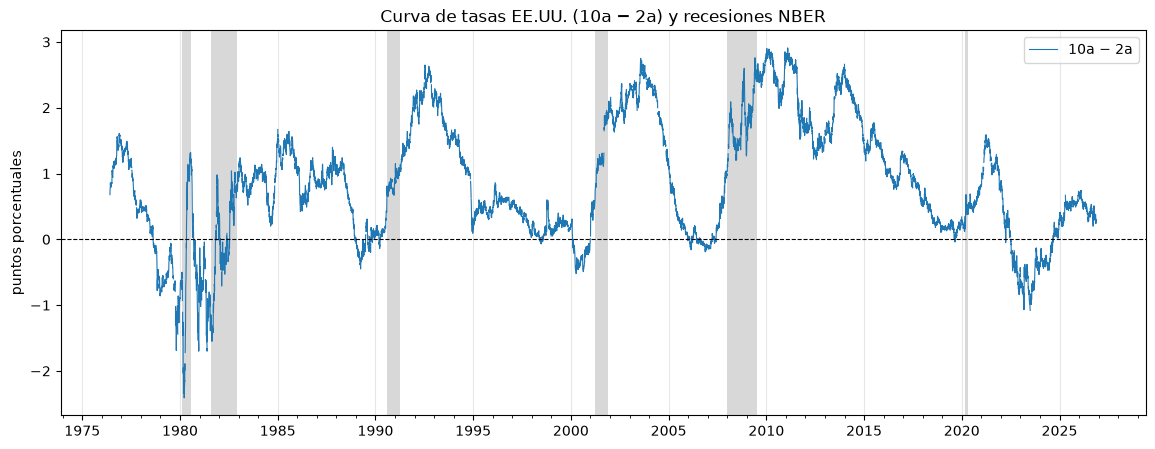

In [12]:
#el gráfico
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# USREC arranca en 1854: lo recortamos al rango de la curva
rec = recesion[recesion.index >= curva.index.min()]

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(curva.index, curva, linewidth=0.8, label="10a − 2a")
ax.axhline(0, color="black", linewidth=0.8, linestyle="--")  # debajo de esta línea = invertida

# Sombrear cada mes de recesión: desde el día 1 de ese mes hasta el día 1 del siguiente
for fecha in rec.index[rec == 1]:
    ax.axvspan(fecha, fecha + pd.offsets.MonthBegin(1), color="grey", alpha=0.3, linewidth=0)

ax.set_title("Curva de tasas EE.UU. (10a − 2a) y recesiones NBER")
ax.set_ylabel("puntos porcentuales")
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator(5))              # número cada 5 años
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))       # mostrar solo el año
ax.xaxis.set_minor_locator(mdates.YearLocator(1))              # rayita cada año
ax.grid(axis="x", which="major", alpha=0.3)  
plt.show()